# Principal component analysis applied to Swiss bank notes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Data from Flury, B. & Riedwyl, H. (1988) Multivariate Statistics: A Practical Approach. Six measurements (in mm) of 200 old Swiss bank notes of 1000 francs, 100 genuine and 100 counterfeit.

| Variable | Description |
|---|---|
| `Length` | length of the note |
| `Left` | height of the note, measured on the left |
| `Right` | height of the note, measured on the right |
| `Bottom` | distance of the inner frame to the lower border |
| `Top` | distance of the inner frame to the upper border |
| `Diagonal` | length of the diagonal |

The column `conterfeit` (sic) is 1 for the counterfeit notes. We do not use it to compute the principal components, only to color the plots.

In [2]:
dat = pd.read_csv('banknotes.csv')

dat

,conterfeit,Length,Left,Right,Bottom,Top,Diagonal
0,0,214.8,131.0,131.1,9.0,9.7,141.0
1,0,214.6,129.7,129.7,8.1,9.5,141.7
2,0,214.8,129.7,129.7,8.7,9.6,142.2
3,0,214.8,129.7,129.6,7.5,10.4,142.0
4,0,215.0,129.6,129.7,10.4,7.7,141.8
...,...,...,...,...,...,...,...
195,1,215.0,130.4,130.3,9.9,12.1,139.6
196,1,215.1,130.3,129.9,10.3,11.5,139.7
197,1,214.8,130.3,130.4,10.6,11.1,140.0
198,1,214.7,130.7,130.8,11.2,11.2,139.4


In [3]:
features = dat.columns.drop('conterfeit')
status = dat['conterfeit'].map({0: 'Genuine', 1: 'Counterfeit'})
status_colors = {'Genuine': '#0072B2', 'Counterfeit': '#E69F00'}

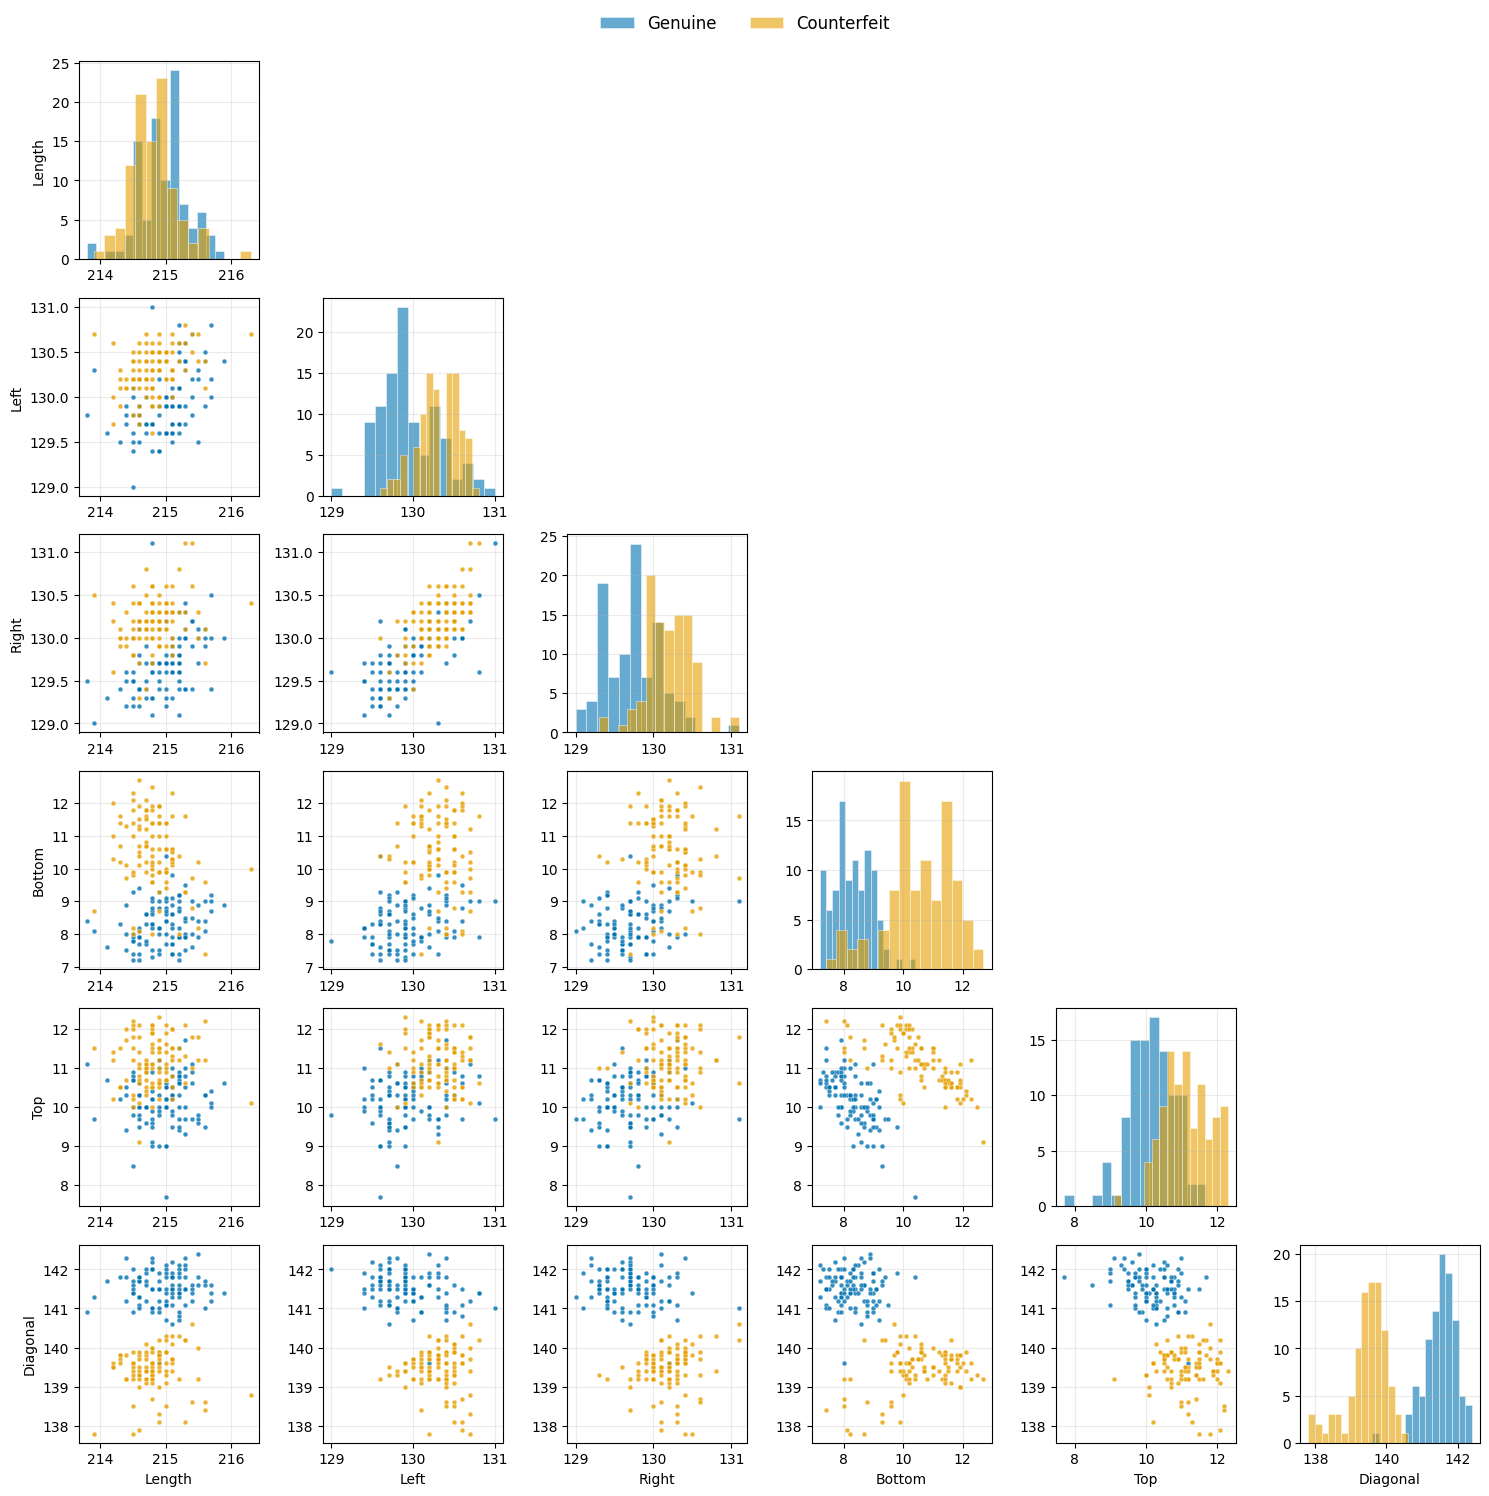

In [4]:
fig, axes = plt.subplots(6, 6, figsize=(15, 15))
for i, feature_i in enumerate(features):
    for j, feature_j in enumerate(features):
        ax = axes[i, j]
        if j > i:
            ax.set_axis_off()
            continue
        for name, color in status_colors.items():
            rows = dat[status == name]
            if i == j:
                ax.hist(rows[feature_i], bins=15, color=color, alpha=0.6, edgecolor='white', linewidth=0.5, label=name)
            else:
                ax.plot(rows[feature_j], rows[feature_i], 'o', color=color, markersize=3.5, markeredgecolor='white',
                        markeredgewidth=0.3, alpha=0.8)
        ax.grid(True, alpha=0.25)
        if j == 0:
            ax.set_ylabel(feature_i)
        if i == 5:
            ax.set_xlabel(feature_j)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.97))

## Three ways of computing the principal components

With $X$ the centered data matrix, $S$ its covariance matrix, and the singular value decomposition $X = UDV^T$:

- the loadings (directions of the components) are the columns of $V$, which are the eigenvectors of $S$,
- the variances of the components are $d_j^2/(n-1)$, the eigenvalues of $S$,
- the components (scores) are $UD = XV$.

In [5]:
class PCA_several_methods:
    def __init__(self, dat):
        X = dat.drop('conterfeit', axis=1)
        self.n, self.p = X.shape
        self.X = X

    def center_X(self):
        self.X_centered = pd.DataFrame(StandardScaler(with_std=False).fit_transform(self.X))

    def compute_S(self):
        self.S = self.X.cov()

    def SVD(self):
        self.u, self.d, self.v_T  = np.linalg.svd(self.X_centered, full_matrices=False)

    def check_SVD(self):
        return(self.u @ np.diag(self.d) @ self.v_T)

    def PCA_with_SVD(self):
        self.SVD_loads       = self.v_T.T
        self.SVD_variance_PC = self.d**2/(self.n-1)
        self.SVD_PC_UD       = (self.u @ np.diag(self.d))
        self.SVD_PC_V        = self.X_centered @ self.v_T.T

    def PCA_with_cov_matrix(self):
        # eigh: for symmetric matrices, real eigenvalues in increasing order. We want them decreasing
        eigval, eigvect    = np.linalg.eigh(self.S)
        order              = np.argsort(-eigval)
        self.S_loads       = eigvect[:, order]
        self.S_variance_PC = eigval[order]
        self.S_PC          = self.X_centered @ self.S_loads

    def PCA_with_sklearn(self):
        pca                      = PCA(n_components = self.p)
        pca_fit                  = pca.fit_transform(self.X)
        self.sklearn_loads       = pca.components_.T
        self.sklearn_variance_PC = pca.explained_variance_
        self.sklearn_PC          = pca_fit

In [6]:
pca_several = PCA_several_methods(dat)
pca_several.center_X()
pca_several.compute_S()
pca_several.SVD()

pca_several.X_centered.head()

,0,1,2,3,4,5
0,-0.096,0.8785,1.1435,-0.4175,-0.9505,0.5165
1,-0.296,-0.4215,-0.2565,-1.3175,-1.1505,1.2165
2,-0.096,-0.4215,-0.2565,-0.7175,-1.0505,1.7165
3,-0.096,-0.4215,-0.3565,-1.9175,-0.2505,1.5165
4,0.104,-0.5215,-0.2565,0.9825,-2.9505,1.3165


The SVD reproduces the centered matrix

In [7]:
print('Largest difference:', np.max(np.abs(pca_several.check_SVD() - pca_several.X_centered.to_numpy())))

Largest difference: 5.329070518200751e-15


### PCA through SVD

In [8]:
pca_several.PCA_with_SVD()
pd.DataFrame(pca_several.SVD_loads, index=features).round(4)

,0,1,2,3,4,5
Length,0.0438,-0.0107,-0.3263,0.5617,-0.7526,0.0981
Left,-0.1122,-0.0714,-0.2590,0.4555,0.3468,-0.7665
Right,-0.1392,-0.0663,-0.3447,0.4153,0.5347,0.6317
Bottom,-0.7683,0.5631,-0.2180,-0.1861,-0.1000,-0.0222
Top,-0.2018,-0.6593,-0.5567,-0.4507,-0.1019,-0.0349
Diagonal,0.5789,0.4885,-0.5918,-0.2584,0.0845,-0.0457


In [9]:
pca_several.SVD_variance_PC

array([3.00030487, 0.93562052, 0.24341371, 0.19465874, 0.08521185,
       0.03551468])

In [10]:
# The components computed as UD and as XV are the same
print('Largest difference:', np.max(np.abs(pca_several.SVD_PC_UD - pca_several.SVD_PC_V.to_numpy())))
pd.DataFrame(pca_several.SVD_PC_UD).head().round(4)

Largest difference: 6.217248937900877e-15


,0,1,2,3,4,5
0,0.5496,0.5064,-0.2759,1.1937,1.1705,0.0584
1,2.0186,0.6613,0.5020,-0.0154,0.2911,0.1458
2,1.8357,1.1753,-0.0456,-0.1891,0.1127,0.1258
3,2.4944,-0.1189,-0.0765,-0.3161,0.0808,0.0705
4,0.7013,3.1948,0.8388,0.5210,-0.0826,0.2688


### PCA through the covariance matrix

In [11]:
pca_several.PCA_with_cov_matrix()
pd.DataFrame(pca_several.S_loads, index=features).round(4)

,0,1,2,3,4,5
Length,-0.0438,-0.0107,0.3263,0.5617,-0.7526,0.0981
Left,0.1122,-0.0714,0.2590,0.4555,0.3468,-0.7665
Right,0.1392,-0.0663,0.3447,0.4153,0.5347,0.6317
Bottom,0.7683,0.5631,0.2180,-0.1861,-0.1000,-0.0222
Top,0.2018,-0.6593,0.5567,-0.4507,-0.1019,-0.0349
Diagonal,-0.5789,0.4885,0.5918,-0.2584,0.0845,-0.0457


In [12]:
pca_several.S_variance_PC

array([3.00030487, 0.93562052, 0.24341371, 0.19465874, 0.08521185,
       0.03551468])

### PCA with sklearn

In [13]:
pca_several.PCA_with_sklearn()
pd.DataFrame(pca_several.sklearn_loads, index=features).round(4)

,0,1,2,3,4,5
Length,-0.0438,0.0107,0.3263,0.5617,0.7526,-0.0981
Left,0.1122,0.0714,0.2590,0.4555,-0.3468,0.7665
Right,0.1392,0.0663,0.3447,0.4153,-0.5347,-0.6317
Bottom,0.7683,-0.5631,0.2180,-0.1861,0.1000,0.0222
Top,0.2018,0.6593,0.5567,-0.4507,0.1019,0.0349
Diagonal,-0.5789,-0.4885,0.5918,-0.2584,-0.0845,0.0457


In [14]:
pca_several.sklearn_variance_PC

array([3.00030487, 0.93562052, 0.24341371, 0.19465874, 0.08521185,
       0.03551468])

### The three methods agree

The variances are the same. The loadings are the same up to the sign: if $v$ is an eigenvector, so is $-v$, and each method can return either.

In [15]:
pd.DataFrame({
    'variances': [np.max(np.abs(pca_several.SVD_variance_PC - pca_several.S_variance_PC)),
                  np.max(np.abs(pca_several.SVD_variance_PC - pca_several.sklearn_variance_PC))],
    'loadings (absolute values)': [np.max(np.abs(np.abs(pca_several.SVD_loads) - np.abs(pca_several.S_loads))),
                                   np.max(np.abs(np.abs(pca_several.SVD_loads) - np.abs(pca_several.sklearn_loads)))]},
    index=['SVD vs covariance matrix', 'SVD vs sklearn']).rename_axis('largest difference')

,variances,loadings (absolute values)
largest difference,,
SVD vs covariance matrix,3.108624e-15,5.162537e-15
SVD vs sklearn,8.625226e-12,2.298861e-11


## How many components?

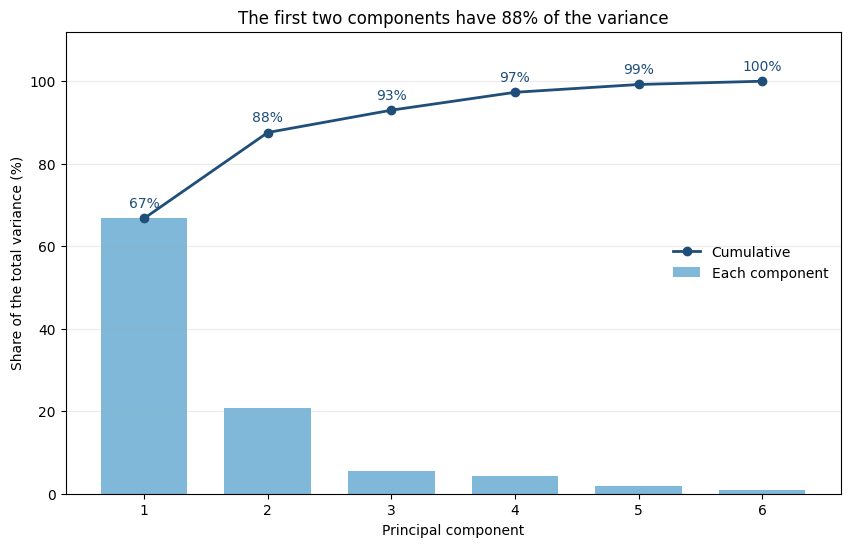

In [16]:
variance = pca_several.sklearn_variance_PC
share = variance/variance.sum()

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(range(1, 7), 100*share, color='#7fb8d8', width=0.7, label='Each component')
ax.plot(range(1, 7), 100*share.cumsum(), 'o-', color='#1f4e79', lw=2, label='Cumulative')
for i, value in enumerate(100*share.cumsum()):
    ax.annotate(f'{value:.0f}%', (i+1, value), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=10,
                color='#1f4e79')
ax.set_ylim(0, 112)
ax.set_xlabel('Principal component')
ax.set_ylabel('Share of the total variance (%)')
ax.set_title('The first two components have 88% of the variance')
ax.legend(loc='center right', frameon=False)
ax.grid(True, axis='y', alpha=0.25)

## Loadings and components

In [17]:
loads = pd.DataFrame(pca_several.sklearn_loads, index=features, columns=[f'PC{j+1}' for j in range(6)])

loads.round(4)

,PC1,PC2,PC3,PC4,PC5,PC6
Length,-0.0438,0.0107,0.3263,0.5617,0.7526,-0.0981
Left,0.1122,0.0714,0.2590,0.4555,-0.3468,0.7665
Right,0.1392,0.0663,0.3447,0.4153,-0.5347,-0.6317
Bottom,0.7683,-0.5631,0.2180,-0.1861,0.1000,0.0222
Top,0.2018,0.6593,0.5567,-0.4507,0.1019,0.0349
Diagonal,-0.5789,-0.4885,0.5918,-0.2584,-0.0845,0.0457


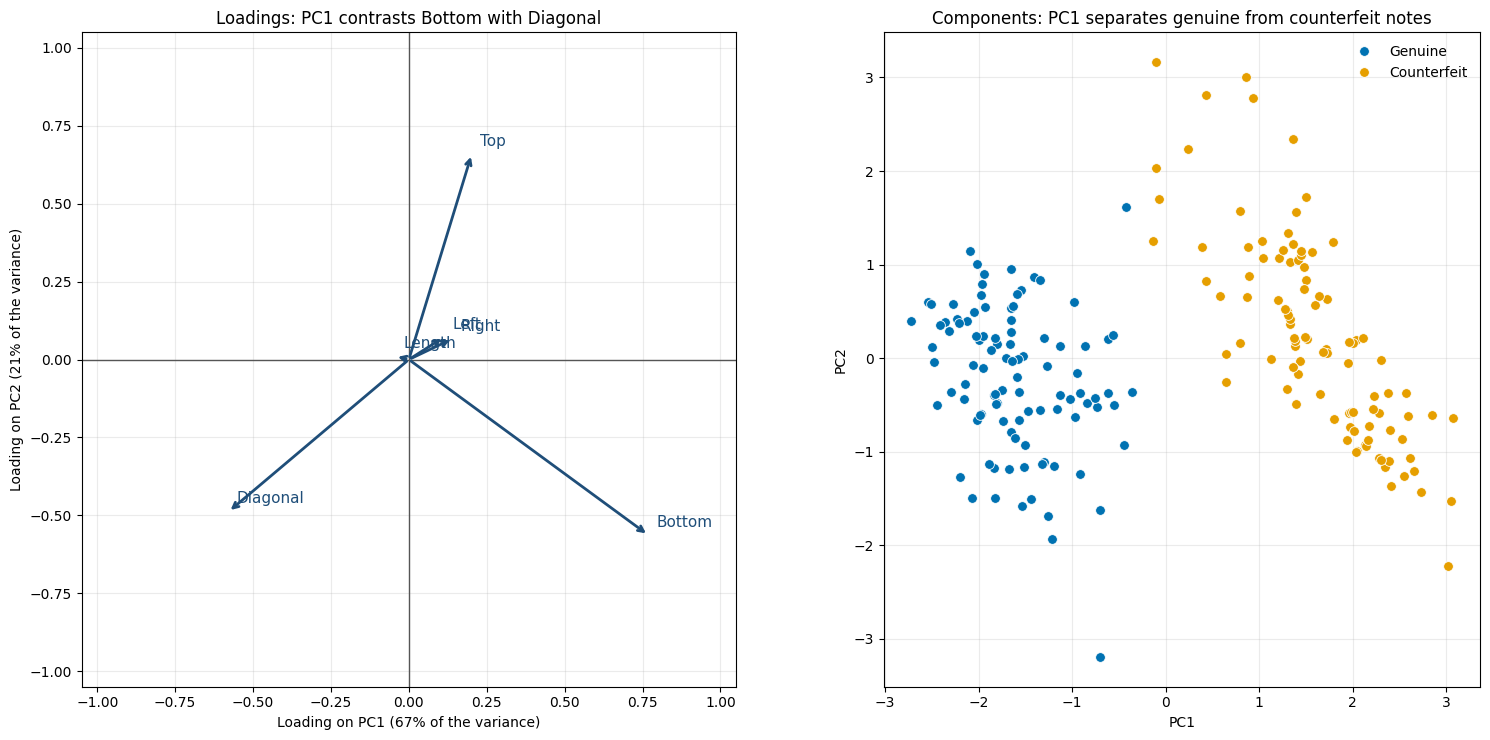

In [18]:
Components = pd.DataFrame(pca_several.sklearn_PC, columns=loads.columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))

ax = axes[0]
ax.axvline(0, color='#555555', lw=1)
ax.axhline(0, color='#555555', lw=1)
for feature in features:
    ax.annotate('', (loads.loc[feature, 'PC1'], loads.loc[feature, 'PC2']), (0, 0),
                arrowprops=dict(arrowstyle='->', color='#1f4e79', lw=2))
    ax.annotate(feature, (loads.loc[feature, 'PC1'], loads.loc[feature, 'PC2']), xytext=(6, 6),
                textcoords='offset points', fontsize=11, color='#1f4e79')
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)
ax.set_aspect('equal')
ax.set_xlabel(f'Loading on PC1 ({100*share[0]:.0f}% of the variance)')
ax.set_ylabel(f'Loading on PC2 ({100*share[1]:.0f}% of the variance)')
ax.set_title('Loadings: PC1 contrasts Bottom with Diagonal')
ax.grid(True, alpha=0.25)

ax = axes[1]
for name, color in status_colors.items():
    rows = Components[(status == name).to_numpy()]
    ax.plot(rows['PC1'], rows['PC2'], 'o', color=color, markersize=7, markeredgecolor='white', markeredgewidth=0.6,
            label=name)
ax.set_aspect('equal')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('Components: PC1 separates genuine from counterfeit notes')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)
plt.tight_layout()

The principal components were computed without knowing which notes are counterfeit, and still the first one separates them almost perfectly: the counterfeit notes have a larger bottom margin and a shorter diagonal.

### Biplot

Components and loadings in the same plot (the loadings are multiplied by a constant to be visible).

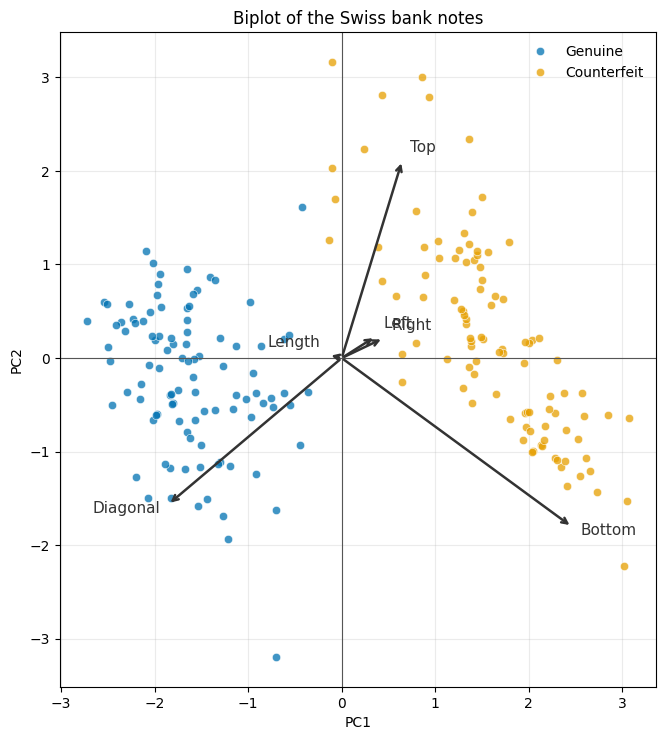

In [19]:
fig, ax = plt.subplots(figsize=(11, 8.5))
for name, color in status_colors.items():
    rows = Components[(status == name).to_numpy()]
    ax.plot(rows['PC1'], rows['PC2'], 'o', color=color, markersize=6, markeredgecolor='white', markeredgewidth=0.5,
            alpha=0.75, label=name)
scale = 3.2
for feature in features:
    tip = scale*loads.loc[feature, ['PC1', 'PC2']].to_numpy()
    ax.annotate('', tip, (0, 0), arrowprops=dict(arrowstyle='->', color='#333333', lw=1.8))
    ax.annotate(feature, tip, xytext=(6*np.sign(tip[0]), 6*np.sign(tip[1])), textcoords='offset points',
                ha='left' if tip[0] >= 0 else 'right', fontsize=11, color='#333333')
ax.axvline(0, color='#555555', lw=0.8)
ax.axhline(0, color='#555555', lw=0.8)
ax.set_aspect('equal')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('Biplot of the Swiss bank notes')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)